# Chapter 5: Decision Trees

**Student Learning Version**  
Work through this notebook to understand decision trees. The solution notebook will be provided after completion.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns; sns.set()
from matplotlib.colors import ListedColormap
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn import metrics
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report

## 5.1 Introduction & Motivation

Welcome to the fascinating world of decision trees! In this chapter, we'll explore one of the most intuitive and interpretable machine learning algorithms available to data scientists today.

Now that we've gained a solid foundation in classification models, we'll advance our understanding by introducing one of the most intuitive and interpretable classifiers: **decision trees**.

Decision trees mirror the way humans naturally make decisions by breaking down complex problems into a series of simple yes/no questions. This makes them particularly valuable for understanding how predictions are made, unlike "black box" algorithms where the decision-making process is opaque.

Consider the following decision tree, which demonstrates how we can systematically classify animals into their respective families using a series of logical questions:

![](https://github.com/jakevdp/PythonDataScienceHandbook/blob/master/notebooks/figures/05.08-decision-tree.png?raw=1)

This animal classification tree perfectly illustrates how decision trees work in practice. Each internal node (like "Has fur?") represents a decision based on a feature, each branch represents the outcome of that decision, and each leaf node represents the final classification.

While we could manually construct such a tree using countless $if-else$ statements, the real power of decision trees lies in their ability to automatically learn these decision rules from data. Machine learning algorithms can analyze datasets and determine the optimal sequence of questions to ask, creating decision trees that can classify new, unseen examples with remarkable accuracy.

**Key advantages of decision trees:**
- **Interpretability**: The decision-making process is transparent and easy to explain
- **No assumptions**: They don't require assumptions about data distribution
- **Handles mixed data types**: Can work with both numerical and categorical features
- **Feature selection**: Automatically identifies the most important features

## 5.2 Problem Setting: Penguin Species Classification

To demonstrate the power and interpretability of decision trees, we'll tackle a real-world biology problem: identifying the **species of a penguin** from a few simple body measurements.

We'll use the **Palmer Penguins** dataset. The data was collected by Dr. Kristen Gorman at Palmer Station, Antarctica, and contains measurements of three penguin species:

| Species | Description |
|---|---|
| **Adelie** | The smallest of the three, with a short bill |
| **Chinstrap** | Named after the thin black line under its head |
| **Gentoo** | The largest of the three, with long flippers |

**Dataset Overview:**
Each row describes one penguin. The columns are:
- `species`: the penguin species — this is our **target** (what we want to predict)
- `island`: the island where the penguin was observed (Biscoe, Dream or Torgersen)
- `bill_length_mm` and `bill_depth_mm`: the length and depth (height) of the bill
- `flipper_length_mm`: the length of the flipper (wing)
- `body_mass_g`: the body mass in grams
- `sex`: male or female

This dataset is a great fit for decision trees: it has only a few features, the features are easy to understand, and the tree we learn can be read just like the animal tree above.

The dataset ships with seaborn, so we can load it with one line of code (an internet connection is needed the first time):

In [2]:
penguins = sns.load_dataset('penguins')
penguins.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female


In [3]:
# Shape of the dataset: (rows, columns)
print("Data Shape:", penguins.shape)

# Number of missing values per column
penguins.isna().sum()

Data Shape: (344, 7)


species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
dtype: int64

A few penguins have missing measurements. Since there are only a handful of them, we simply remove those rows:

In [4]:
penguins = penguins.dropna()
print("Data Shape after removing missing values:", penguins.shape)

Data Shape after removing missing values: (333, 7)


### 5.2.1 Exploratory Data Analysis: How Different Are the Species?

Before we train any model, let's look at the data. A decision tree will search for simple questions like *"Is the flipper longer than 206 mm?"* to separate the species. If we can already spot such differences in a few plots, we'll better understand the tree that the algorithm builds later on.

**How many penguins of each species do we have?**

species
Adelie       146
Gentoo       119
Chinstrap     68
Name: count, dtype: int64


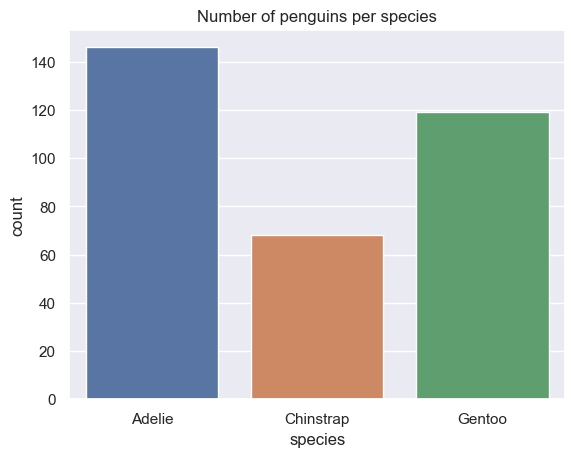

In [5]:
species_order = ['Adelie', 'Chinstrap', 'Gentoo']

print(penguins['species'].value_counts())

sns.countplot(data=penguins, x='species', hue='species', order=species_order)
plt.title('Number of penguins per species');

The classes are **not perfectly balanced**: there are about twice as many Adelie penguins as Chinstrap penguins. Keep this in mind when we look at the evaluation metrics per species later on.

**What does an average penguin of each species look like?**

In [6]:
penguins.groupby('species').mean(numeric_only=True).round(1)

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
species,,,,
Adelie,38.8,18.3,190.1,3706.2
Chinstrap,48.8,18.4,195.8,3733.1
Gentoo,47.6,15.0,217.2,5092.4


**How are the measurements distributed per species?**

A boxplot per feature lets us compare the species side by side:

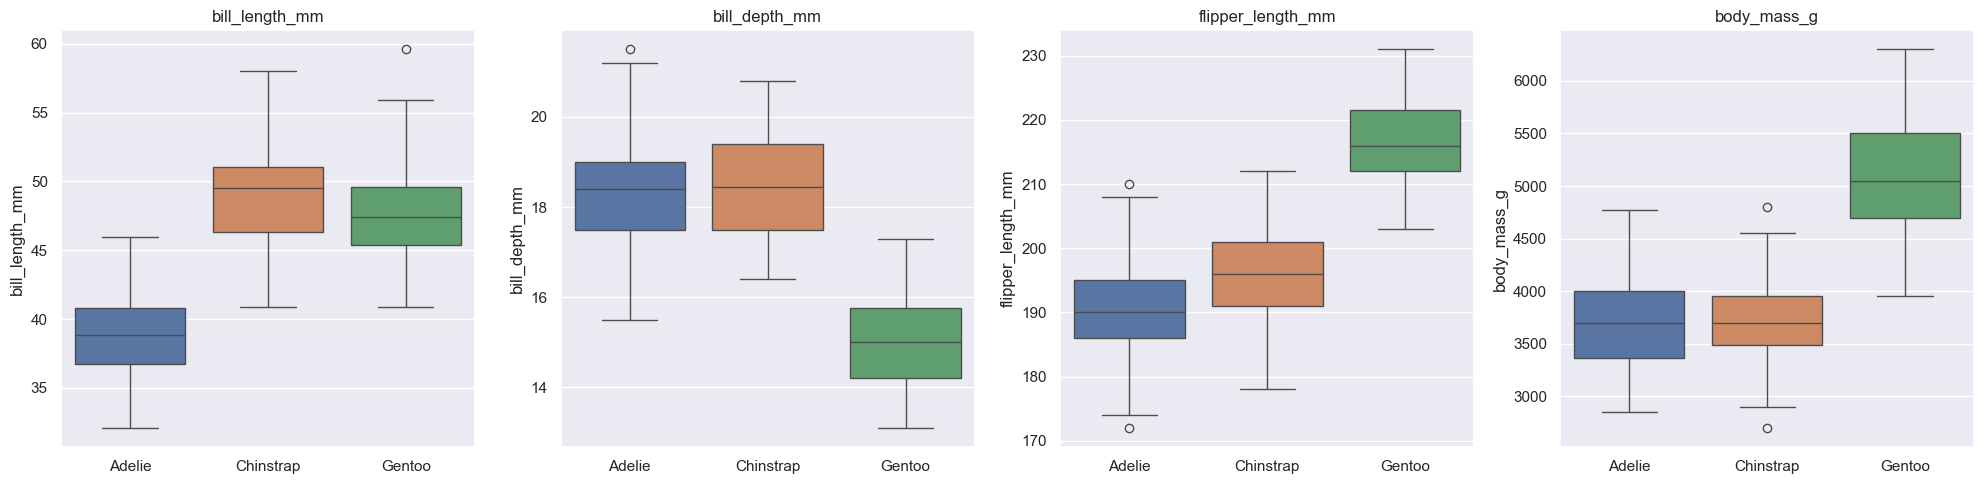

In [7]:
features = ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']

fig, axes = plt.subplots(1, 4, figsize=(20, 5))
for ax, feature in zip(axes, features):
    sns.boxplot(data=penguins, x='species', y=feature, hue='species', order=species_order, ax=ax)
    ax.set_title(feature)
    ax.set_xlabel('')
plt.tight_layout()

**What do we see?**
- **Gentoo** penguins stand out: they have much **longer flippers**, are much **heavier** and have a **shallower bill** than the other two species.
- **Adelie** and **Chinstrap** penguins have very similar flippers, body mass and bill depth...
- ...but **Chinstrap** penguins have a much **longer bill** than Adelie penguins.

No single feature separates all three species, but a **combination of two features** might. Let's look at all pairs of features at once with a pairplot:

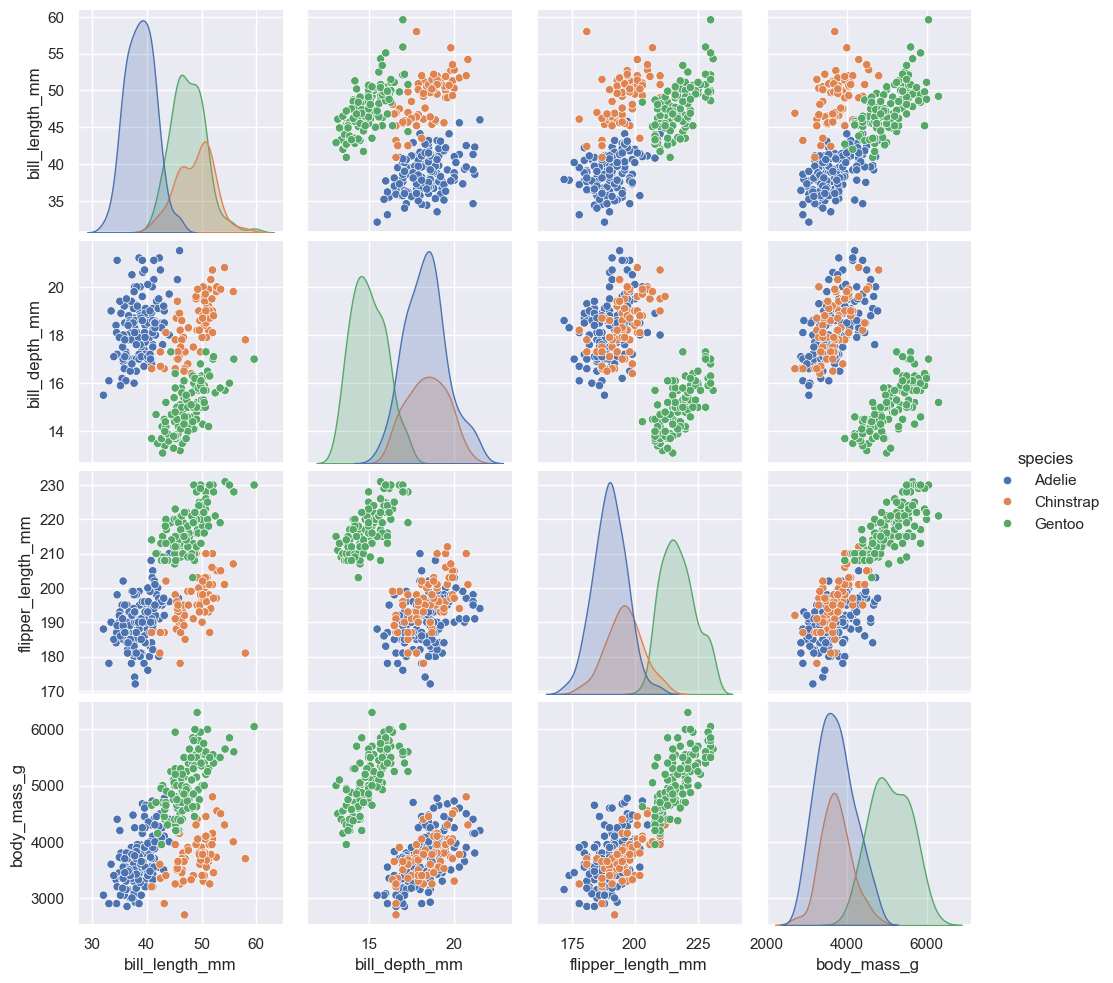

In [8]:
sns.pairplot(penguins, hue='species', hue_order=species_order, height=2.5);

The plots combining **bill length** with another feature (for example flipper length or bill depth) show three clearly separated groups. Only a few points lie in the overlap zone between the species. This is exactly the kind of structure a decision tree can exploit.

**Is the island informative too?**

In [9]:
pd.crosstab(penguins['island'], penguins['species'])

species,Adelie,Chinstrap,Gentoo
island,,,
Biscoe,44,0,119
Dream,55,68,0
Torgersen,47,0,0


Gentoo penguins only live on Biscoe, Chinstrap penguins only on Dream, and Torgersen is home to Adelie penguins only. The island is a strong clue, but on its own it cannot tell Adelie apart from the other species on Biscoe and Dream. To keep things simple, we'll build our model with the **four numerical measurements** only.

## 5.3 Understanding Decision Trees: From Theory to Practice

Decision trees work by recursively partitioning the feature space into regions that are as homogeneous as possible with respect to the target variable. Let's explore how this process works both theoretically and practically.

### 5.3.1 The Decision Tree Algorithm: How It Works

Understanding decision trees conceptually is crucial before diving into implementation. While the mathematical foundations involve concepts like information gain, entropy, and Gini impurity, we'll focus on the intuitive understanding that makes decision trees so appealing.

The concrete mathematical setup of decision tree classifiers involves sophisticated concepts from information theory. However, the beauty of decision trees lies in their intuitive nature, which we can understand through visual examples.

**Core Concept**: Decision trees work by asking a series of questions about the features in your data, with each question designed to split the data into groups that are as "pure" as possible (containing mostly one class).

To illustrate this process, let's take just **two features** of our penguins, so that we can visualize exactly how the algorithm makes its decisions:

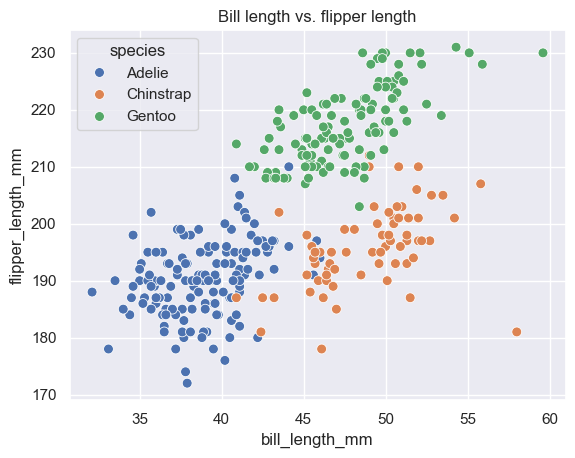

In [10]:
sns.scatterplot(data=penguins, x='bill_length_mm', y='flipper_length_mm',
                hue='species', hue_order=species_order, s=50)
plt.title('Bill length vs. flipper length');

**Understanding the Visualization:**
- **X-axis and Y-axis**: These represent two independent variables (features) in our dataset: bill length and flipper length
- **Colors**: Each color represents a different class (species) that we want to predict
- **Goal**: Create a decision tree that can accurately classify a new penguin based on these two measurements

This scatter plot shows three groups of penguins. A human can easily see the patterns, but how does a computer algorithm learn to distinguish between these groups?

**The Decision Tree Learning Process:**

When a decision tree algorithm analyzes this data, it follows these steps:

1. **Initial Assessment**: Start with all data points mixed together
2. **Find the Best Split**: Identify the feature and threshold that best separates the classes
3. **Create Branches**: Split the data into two groups based on this criterion
4. **Repeat Recursively**: Apply the same process to each new group
5. **Stop When Pure**: Continue until each group contains mostly one class or meets stopping criteria

**Key Insight**: The algorithm draws lines (splits) through the feature space, with each line representing a decision boundary. These lines are always parallel to the axes because each split considers only one feature at a time.

The following diagram illustrates how this iterative splitting process creates increasingly pure regions:

![](https://github.com/jakevdp/PythonDataScienceHandbook/blob/master/notebooks/figures/05.08-decision-tree-levels.png?raw=1)

Let's see the same process on our penguins. We train a tree on the two features above and allow it to grow **one level deeper** in every plot. The colored background shows which species the tree predicts in each region:

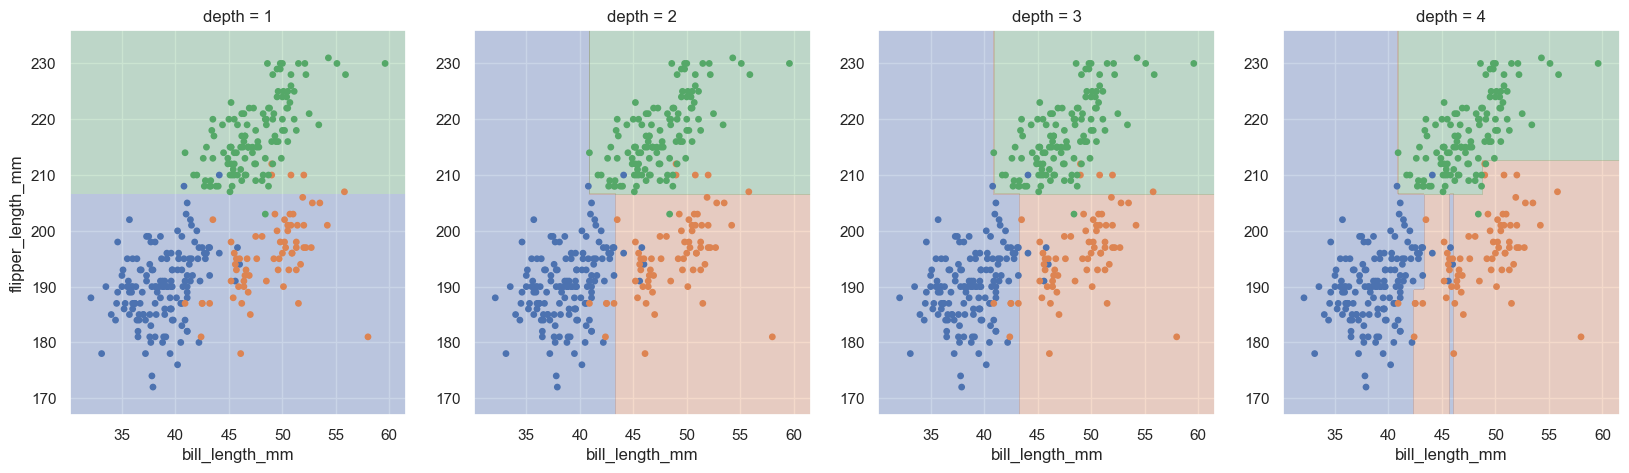

In [11]:
X_2d = penguins[['bill_length_mm', 'flipper_length_mm']]
y_2d = penguins['species']

# Use the same colors as seaborn: Adelie = blue, Chinstrap = orange, Gentoo = green
species_cmap = ListedColormap(sns.color_palette(n_colors=3))

# A grid of points covering the whole plot, used to color the background
xx, yy = np.meshgrid(np.linspace(X_2d.iloc[:, 0].min() - 2, X_2d.iloc[:, 0].max() + 2, 300),
                     np.linspace(X_2d.iloc[:, 1].min() - 5, X_2d.iloc[:, 1].max() + 5, 300))
grid = pd.DataFrame(np.c_[xx.ravel(), yy.ravel()], columns=X_2d.columns)

fig, axes = plt.subplots(1, 4, figsize=(20, 5))
for ax, depth in zip(axes, [1, 2, 3, 4]):
    tree_2d = DecisionTreeClassifier(max_depth=depth, random_state=0).fit(X_2d, y_2d)
    # Convert the predicted species names to numbers (0, 1, 2) so we can color the regions
    regions = pd.Categorical(tree_2d.predict(grid), categories=species_order).codes.reshape(xx.shape)
    ax.contourf(xx, yy, regions, alpha=0.3, cmap=species_cmap, levels=[-0.5, 0.5, 1.5, 2.5])
    ax.scatter(X_2d.iloc[:, 0], X_2d.iloc[:, 1], s=15, cmap=species_cmap,
               c=pd.Categorical(y_2d, categories=species_order).codes)
    ax.set_title(f'depth = {depth}')
    ax.set_xlabel('bill_length_mm')
axes[0].set_ylabel('flipper_length_mm');

- **Depth 1**: one single question (one line) already separates most Gentoo penguins (green) from the others.
- **Depth 2**: a second question on bill length separates Adelie (blue) from Chinstrap (orange).
- **Depth 3 and 4**: the tree keeps adding smaller and smaller rectangles to fix the last few mistakes. Notice how these extra regions become very specific to individual penguins: this is the first sign of **overfitting**.

### 5.3.2 Model Implementation and Training

Now that we understand the theory behind decision trees, let's implement one using scikit-learn and apply it to all four measurements of our penguins. The implementation process follows the standard machine learning workflow we've established in previous chapters.

**Step 1: Data Preparation**

We separate the features (`X`) from the target (`y`). Following machine learning best practices, we then split our dataset into training and testing portions. This separation is crucial for obtaining unbiased estimates of our model's performance.

Because the species are not balanced, we use `stratify=y`: this keeps the same proportion of each species in the training set and in the test set.

In [12]:
X = penguins[features]
y = penguins['species']

x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0, stratify=y)
print("Training set:", x_train.shape)
print("Test set:", x_test.shape)

Training set: (249, 4)
Test set: (84, 4)


**Step 2: Model Creation and Training**

Similar to our Logistic Regression implementation, we instantiate a decision tree classifier and train it on our data. The scikit-learn implementation handles all the complex mathematics behind the scenes. We set `random_state=0` so that everyone gets the same tree:

In [13]:
tree = DecisionTreeClassifier(random_state=0)
tree_fit = tree.fit(x_train, y_train)

**Step 3: Visualizing the Tree**

The biggest advantage of a decision tree is that we can **look inside** the model. Each box is a node and shows:
- the **question** asked at that node (e.g. `flipper_length_mm <= 207.5`). If the answer is *True* we go left, otherwise right
- `gini`: the impurity of the node (0 means all penguins in the node belong to the same species)
- `samples`: the number of training penguins that reach this node
- `value`: how many of those penguins belong to each species
- `class`: the species the tree predicts at this node (the majority)

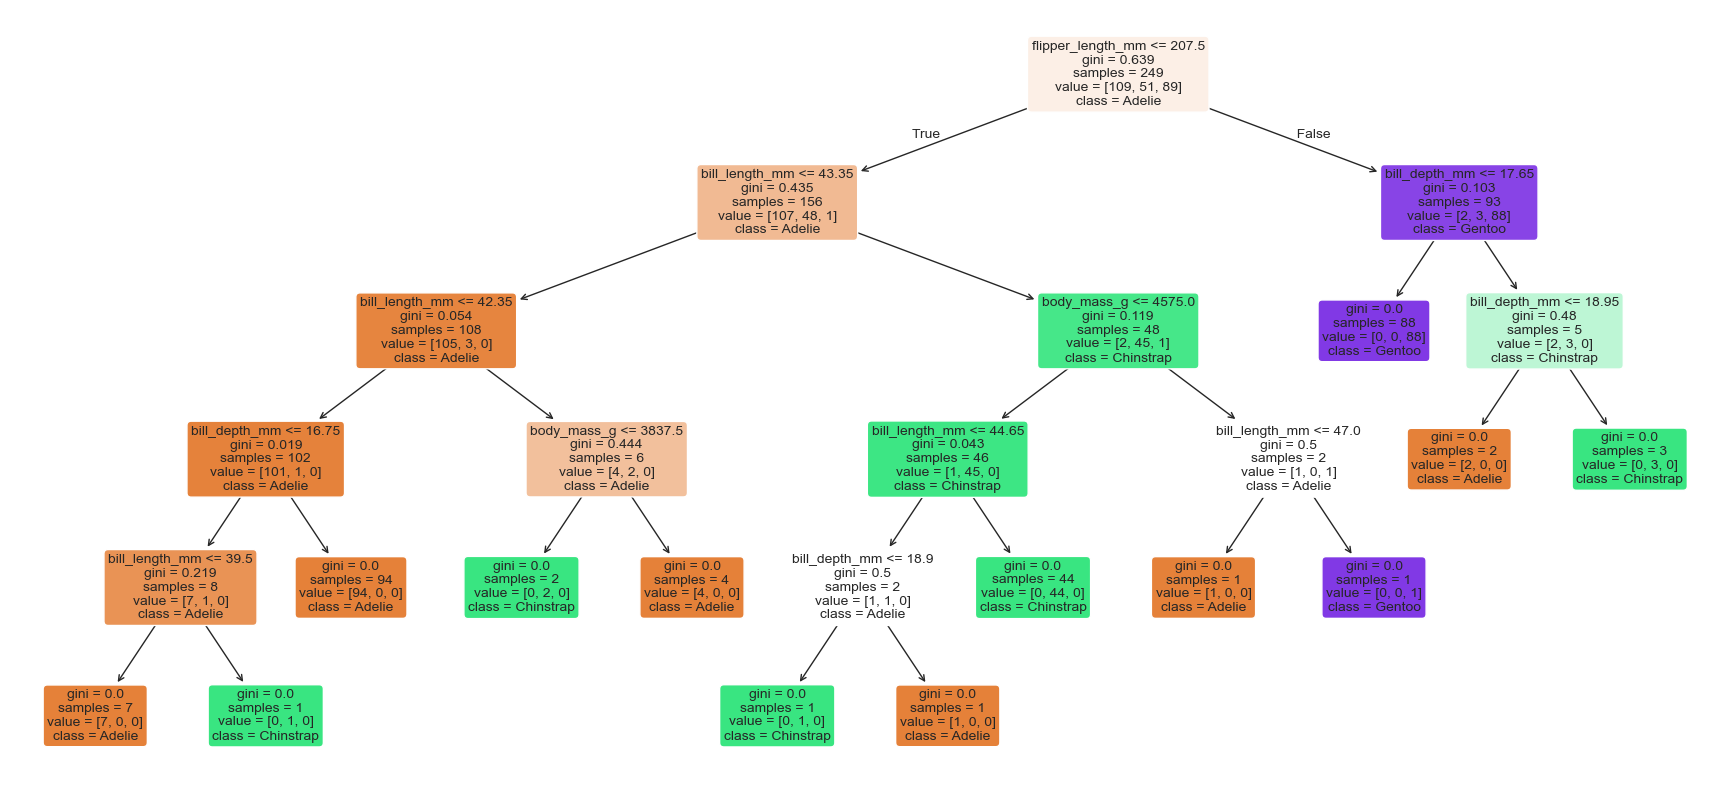

In [14]:
plt.figure(figsize=(22, 10))
plot_tree(tree, feature_names=features, class_names=tree.classes_, filled=True, rounded=True, fontsize=10);

Compare the first questions of the tree with the boxplots from our EDA: the tree discovered **on its own** that flipper length isolates the Gentoo penguins and that bill length separates Adelie from Chinstrap.

We can also ask the model how much each feature contributed to its decisions (the **feature importance**):

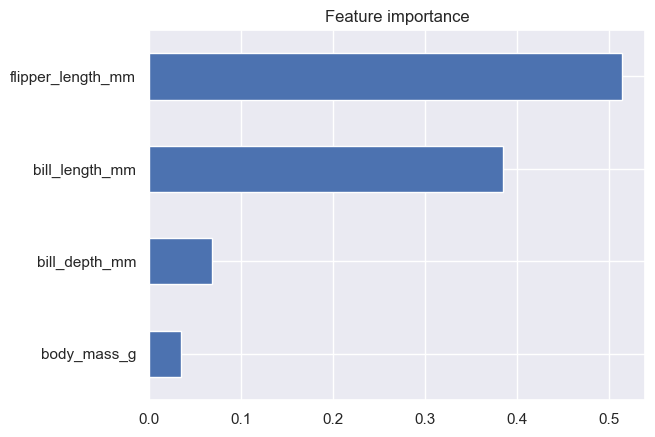

In [15]:
importances = pd.Series(tree.feature_importances_, index=features).sort_values()
importances.plot(kind='barh')
plt.title('Feature importance');

**Step 4: Making Predictions**

With our trained model, we can now make predictions on our test set. Each prediction represents the model's best guess about the species of each test penguin:

In [16]:
predictions = tree.predict(x_test)
print(predictions)

['Chinstrap' 'Chinstrap' 'Adelie' 'Adelie' 'Gentoo' 'Adelie' 'Gentoo'
 'Chinstrap' 'Adelie' 'Chinstrap' 'Chinstrap' 'Chinstrap' 'Gentoo'
 'Gentoo' 'Adelie' 'Adelie' 'Adelie' 'Chinstrap' 'Adelie' 'Gentoo'
 'Gentoo' 'Gentoo' 'Chinstrap' 'Adelie' 'Gentoo' 'Adelie' 'Gentoo'
 'Adelie' 'Adelie' 'Adelie' 'Adelie' 'Adelie' 'Adelie' 'Chinstrap'
 'Adelie' 'Chinstrap' 'Chinstrap' 'Chinstrap' 'Gentoo' 'Gentoo' 'Gentoo'
 'Chinstrap' 'Adelie' 'Gentoo' 'Chinstrap' 'Adelie' 'Adelie' 'Adelie'
 'Gentoo' 'Adelie' 'Adelie' 'Gentoo' 'Chinstrap' 'Gentoo' 'Adelie'
 'Adelie' 'Gentoo' 'Gentoo' 'Gentoo' 'Adelie' 'Adelie' 'Gentoo'
 'Chinstrap' 'Chinstrap' 'Adelie' 'Adelie' 'Adelie' 'Gentoo' 'Gentoo'
 'Gentoo' 'Adelie' 'Adelie' 'Adelie' 'Gentoo' 'Chinstrap' 'Chinstrap'
 'Gentoo' 'Adelie' 'Chinstrap' 'Gentoo' 'Gentoo' 'Gentoo' 'Gentoo'
 'Adelie']


## 5.4 Model Evaluation: Comprehensive Performance Analysis

Evaluating our decision tree's performance requires examining multiple metrics to gain a complete understanding of how well our model performs. We'll use the same evaluation framework established in previous chapters to enable direct comparison with other algorithms.

### Accuracy: The Foundation Metric

**What is Accuracy?**
Accuracy measures the proportion of correct predictions out of all predictions made. It's calculated as:

$$\text{Accuracy} = \frac{\text{Number of Correct Predictions}}{\text{Total Number of Predictions}}$$

This metric provides a quick, intuitive understanding of overall model performance.

Let's calculate our decision tree's accuracy, both on the **training set** (data the model has seen) and on the **test set** (new data). Comparing the two tells us whether the model has learned general rules or simply memorized the training penguins.

In [17]:
train_score = tree_fit.score(x_train, y_train)
score = tree_fit.score(x_test, y_test)
print("Training accuracy:", train_score)
print("Test accuracy:", score)

Training accuracy: 1.0
Test accuracy: 0.9523809523809523


##### Question 1: Interpret the accuracy of this model. What does the difference between the training accuracy and the test accuracy tell you? Look back at the tree you plotted in Step 3: which nodes might be responsible for this difference?

**Your Analysis:**

### Precision, Recall, and F1-Score: Class-Level Performance

While accuracy gives us an overall picture, precision, recall, and F1-score provide deeper insights into how well our model performs for each individual species. These metrics are particularly important for multi-class problems with imbalanced classes, like ours.

In [18]:
print(classification_report(y_test, predictions))

              precision    recall  f1-score   support

      Adelie       0.97      0.92      0.94        37
   Chinstrap       0.85      1.00      0.92        17
      Gentoo       1.00      0.97      0.98        30

    accuracy                           0.95        84
   macro avg       0.94      0.96      0.95        84
weighted avg       0.96      0.95      0.95        84



##### Question 2: Analyze the precision, recall, and F1-scores for each species. Which species does the decision tree classify most accurately, and which one poses the greatest challenge? Use the plots from the EDA (section 5.2.1) to explain why.

**Your Detailed Analysis:**

### Confusion Matrix: Visualizing Classification Patterns

The confusion matrix provides a comprehensive view of our model's classification behavior, showing exactly which species are being confused with others. This visualization is invaluable for understanding systematic errors in our model's predictions.

In [19]:
cm = metrics.confusion_matrix(y_test, predictions)
print(cm)

[[34  3  0]
 [ 0 17  0]
 [ 1  0 29]]


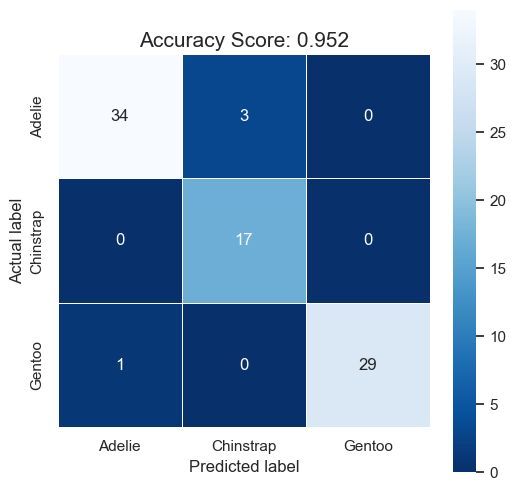

In [20]:
plt.figure(figsize=(6,6))
sns.heatmap(cm, annot=True, fmt="d", linewidths=.5, square = True, cmap = 'Blues_r',
            xticklabels=tree.classes_, yticklabels=tree.classes_);
plt.ylabel('Actual label');
plt.xlabel('Predicted label');
all_sample_title = 'Accuracy Score: {0:.3f}'.format(score)
plt.title(all_sample_title, size = 15);

##### Question 3: Analyze the confusion matrix visualization above. Which species are confused with each other, and in which direction? Look back at the pairplot from section 5.2.1: can you find the penguins that are hard to classify?

**Your Confusion Matrix Analysis:**

## 5.5 Exercises: Deepening Your Understanding

These exercises will help consolidate your understanding of decision trees and develop your skills in comparative model analysis. Work through each question systematically, using both the theoretical concepts and practical results we've explored.

##### Question 4: Comparative Confusion Matrix Analysis
Comparing confusion matrices between different algorithms can be challenging. Create a visual analysis that shows the differences in prediction patterns between Logistic Regression and Decision Tree classifiers on the penguins dataset. Your analysis should help identify where each algorithm excels or struggles.

**Implementation Requirements:**
1. Train both a Logistic Regression and Decision Tree model on the same training set (`x_train`, `y_train`)
2. Generate confusion matrices for both models on the test set
3. Create a visualization showing the difference between the matrices
4. Interpret the results to understand algorithmic differences

In [21]:
from sklearn.linear_model import LogisticRegression

In [22]:
# Your implementation here
# Train both models, generate confusion matrices, and create comparative visualization

**Your Comparative Analysis:**

##### Question 5: Algorithm Comparison and Selection Guidelines

Based on your research and the practical results from this chapter, provide a comprehensive comparison between logistic regression and decision trees. Your analysis should address:

**Performance Characteristics:**
- When does each algorithm typically excel?
- What types of data favor each approach?
- How do computational requirements compare?

**Interpretability and Explainability:**
- Which algorithm provides clearer insights into decision-making?
- When might interpretability be more important than pure accuracy?

**Practical Considerations:**
- Data preprocessing requirements
- Hyperparameter tuning complexity  
- Scalability to large datasets

**Recommendation Framework:**
Develop guidelines for choosing between these algorithms based on project requirements, data characteristics, and business constraints.

**Your Comprehensive Analysis:**

**Logistic Regression Advantages:**

**Decision Tree Advantages:**

**When to Choose Logistic Regression:**

**When to Choose Decision Trees:**

**Recommendation Framework:**